# 01 — Construcción del grafo y validación de rutas

**Práctica 4 · Logística del Valle** (puntos 2 y 4 del enunciado)

En este notebook:

1. Interpretamos la matriz de tiempos y construimos el grafo dirigido de los 40 puntos.
2. Dibujamos la red completa, distinguiendo los sentidos de circulación.
3. Validamos las rutas actuales de las hojas de despacho, de ida y de regreso.
4. Comparamos visualmente, por destino, la ruta actual contra la ruta de menor tiempo de ida y de regreso.

El código de carga y dibujo está en `src/grafo.py` para reutilizarlo en los siguientes notebooks y en la aplicación.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

from src import grafo as g

pd.set_option("display.max_columns", 50)

## 1. La matriz de tiempos

Cada fila es un **origen** y cada columna un **destino**. El valor es el tiempo de viaje en minutos;
`0` es el mismo punto y una celda vacía (`NaN`) indica que no hay conexión directa.

In [2]:
matriz = g.cargar_matriz()
print(f"Dimensión: {matriz.shape[0]} orígenes × {matriz.shape[1]} destinos")
matriz.iloc[:10, :12]

Dimensión: 40 orígenes × 40 destinos


,N01,N02,N03,N04,N05,N06,N07,N08,N09,N10,N11,N12
Origen/Destino,,,,,,,,,,,,
N01,0.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN
N02,8.0,0.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,9.0,NaN,NaN
N03,NaN,8.0,0.0,9.0,NaN,NaN,NaN,NaN,NaN,NaN,8.0,6.0
N04,NaN,NaN,9.0,0.0,10.0,NaN,NaN,NaN,NaN,NaN,9.0,7.0
N05,NaN,NaN,NaN,10.0,0.0,10.0,NaN,NaN,NaN,NaN,NaN,11.0
N06,NaN,NaN,NaN,NaN,10.0,0.0,7.0,NaN,NaN,NaN,NaN,NaN
N07,NaN,NaN,NaN,NaN,NaN,7.0,0.0,7.0,NaN,NaN,NaN,NaN
N08,NaN,NaN,NaN,NaN,NaN,NaN,7.0,0.0,NaN,NaN,NaN,NaN
N09,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,6.0,NaN,NaN


## 2. Construcción del grafo dirigido

Cada celda con un tiempo mayor que cero se convierte en un **arco dirigido** `origen → destino`
con atributo `peso` = minutos. Como la matriz puede ser asimétrica, el arco `A → B` y el arco `B → A`
son independientes: puede existir uno sin el otro, o ambos con tiempos distintos.

Clasificamos cada par de puntos conectados en tres tipos:

| Tipo | Significado |
|---|---|
| **Doble sentido** | Existen `A → B` y `B → A` con el mismo tiempo |
| **Asimétrico** | Existen ambos sentidos, pero con tiempos distintos |
| **Un solo sentido** | Solo existe `A → B` |

In [3]:
G = g.construir_grafo(matriz)

tipos = pd.Series({(u, v): g.tipo_arco(G, u, v) for u, v in G.edges})
resumen = tipos.value_counts().rename("arcos dirigidos").to_frame()
resumen["pares de puntos"] = resumen["arcos dirigidos"] // resumen.index.map(lambda t: 1 if t == "unico" else 2)
print(f"Nodos: {G.number_of_nodes()}   Arcos dirigidos: {G.number_of_edges()}")
print(f"Fuertemente conexo (se puede ir y volver entre cualquier par): {nx.is_strongly_connected(G)}")
resumen

Nodos: 40   Arcos dirigidos: 144
Fuertemente conexo (se puede ir y volver entre cualquier par): True


,arcos dirigidos,pares de puntos
doble,98,49
asimetrico,28,14
unico,18,18


### Calles de un solo sentido

In [4]:
unicos = pd.DataFrame(
    [(u, v, G[u][v]["peso"]) for u, v in G.edges if g.tipo_arco(G, u, v) == "unico"],
    columns=["origen", "destino", "minutos"],
)
unicos

,origen,destino,minutos
0,N01,N17,9.0
1,N02,N10,9.0
2,N02,N18,5.0
3,N11,N13,6.0
4,N15,N23,11.0
5,N17,N26,10.0
6,N18,N26,6.0
7,N20,N19,11.0
8,N20,N29,9.0
9,N21,N20,4.0


### Tramos con tiempos distintos según el sentido

In [5]:
asimetricos = pd.DataFrame(
    [(u, v, G[u][v]["peso"], G[v][u]["peso"]) for u, v in G.edges
     if g.tipo_arco(G, u, v) == "asimetrico" and u < v],
    columns=["A", "B", "min A→B", "min B→A"],
)
asimetricos

,A,B,min A→B,min B→A
0,N03,N12,6.0,8.0
1,N04,N11,9.0,5.0
2,N05,N14,7.0,5.0
3,N06,N15,11.0,8.0
4,N07,N23,7.0,5.0
5,N11,N27,9.0,8.0
6,N16,N23,6.0,5.0
7,N22,N29,5.0,11.0
8,N25,N27,5.0,9.0
9,N26,N33,5.0,8.0


## 3. Representación visual de la red

No se proporciona un mapa, así que hay que elegir una disposición. Los nodos se colocan en una
**cuadrícula de 8 columnas × 5 filas** según su numeración (N01–N08 en la primera fila, N09–N16 en la
segunda, etc.). Es un esquema, no una ubicación geográfica, pero con esta disposición casi todos los
arcos unen puntos vecinos, lo que sugiere que la red sí sigue una estructura de cuadrícula.

Convenciones del dibujo:

- **Sentido de circulación:** las puntas de flecha indican el sentido.
  - Gris con doble punta: doble sentido con el mismo tiempo (se dibuja una sola línea).
  - Naranja: doble sentido con tiempos distintos. Se dibujan dos arcos curvos, uno por sentido.
  - Rojo: un solo sentido.
- **Tiempo de viaje:** la etiqueta sobre cada arco son los minutos en ese sentido.
- Los arcos que en línea recta pasarían encima de otro nodo se dibujan curvos.
- Azul: bodega N01. Verde: destinos.

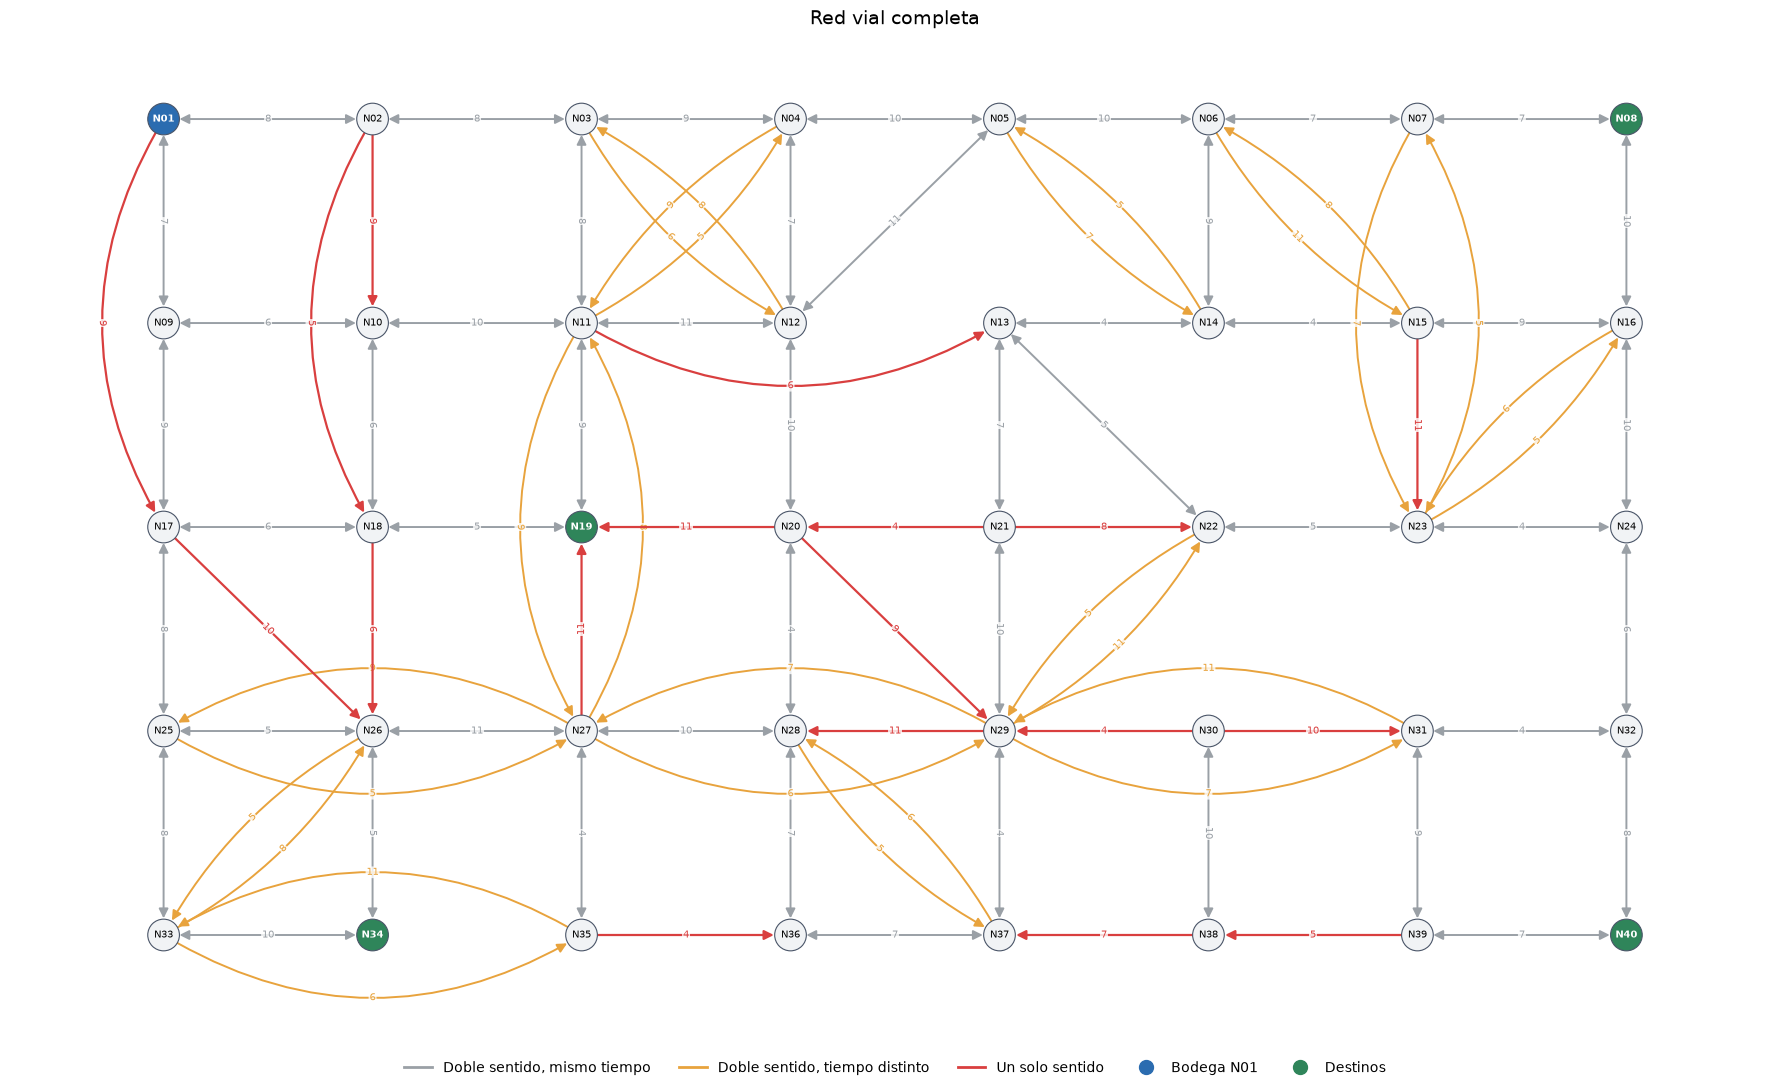

In [6]:
fig, ax = plt.subplots(figsize=(18, 11))
g.dibujar_red(G, ax=ax)
plt.tight_layout()
plt.show()

## 4. Validación de las rutas actuales

Las hojas de despacho indican que el vehículo **regresa por el mismo camino en sentido inverso**.
Para que eso sea posible, cada tramo de la ruta debe existir **en ambos sentidos**. Validamos
tramo por tramo la ida y el regreso.

In [7]:
filas = []
for destino, ida in g.RUTAS_ACTUALES.items():
    regreso = ida[::-1]
    ok_ida, t_ida, _ = g.validar_ruta(G, ida)
    ok_reg, t_reg, _ = g.validar_ruta(G, regreso)
    filas.append({
        "destino": destino,
        "tramos": len(ida) - 1,
        "ida válida": ok_ida,
        "ida (min)": t_ida,
        "regreso válido": ok_reg,
        "regreso (min)": t_reg,
        "ciclo (min)": t_ida + t_reg,
        "ida ≤ 75 min": t_ida <= 75,
    })
validacion_actual = pd.DataFrame(filas).set_index("destino")
validacion_actual

,tramos,ida válida,ida (min),regreso válido,regreso (min),ciclo (min),ida ≤ 75 min
destino,,,,,,,
N08,7,True,59.0,True,59.0,118.0,True
N19,4,True,33.0,True,33.0,66.0,True
N34,5,True,42.0,True,42.0,84.0,True
N40,11,True,93.0,True,93.0,186.0,False


Detalle tramo por tramo (ejemplo: N40, la ruta más larga):

In [8]:
_, _, tabla_ida = g.validar_ruta(G, g.RUTAS_ACTUALES["N40"])
_, _, tabla_reg = g.validar_ruta(G, g.RUTAS_ACTUALES["N40"][::-1])
pd.concat({"Ida": tabla_ida, "Regreso": tabla_reg}, axis=1)

Ida                   Regreso               
        tramo existe minutos      tramo existe minutos
0   N01 → N02   True     8.0  N40 → N32   True     8.0
1   N02 → N03   True     8.0  N32 → N24   True     6.0
2   N03 → N04   True     9.0  N24 → N16   True    10.0
3   N04 → N05   True    10.0  N16 → N08   True    10.0
4   N05 → N06   True    10.0  N08 → N07   True     7.0
5   N06 → N07   True     7.0  N07 → N06   True     7.0
6   N07 → N08   True     7.0  N06 → N05   True    10.0
7   N08 → N16   True    10.0  N05 → N04   True    10.0
8   N16 → N24   True    10.0  N04 → N03   True     9.0
9   N24 → N32   True     6.0  N03 → N02   True     8.0
10  N32 → N40   True     8.0  N02 → N01   True     8.0

**Observaciones**

- Las cuatro rutas actuales son **transitables de ida y de regreso**: todos sus tramos existen en ambos sentidos.
- Sus tiempos de ida y regreso son iguales porque todos los tramos que usan son de doble sentido con el mismo tiempo.
- La ruta actual a **N40 tarda 93 minutos solo de ida**, por encima del umbral de 75 minutos.
  Con esa ruta ninguna entrega a N40 puede ser puntual, aunque el pedido no espere en cola.

## 5. Panorama por destino: ruta actual vs. ruta de menor tiempo

Para tener el panorama completo, comparamos cada ruta actual con la ruta de menor tiempo,
calculada **por separado** para la ida (`N01 → destino`) y para el regreso (`destino → N01`).

> En esta etapa usamos `networkx.dijkstra_path` solo como **referencia**. En la fase 3 implementaremos
> nuestro propio Dijkstra y usaremos estos resultados para verificar que coincide.

En cada figura: verde grueso = ruta de menor tiempo; azul punteado = ruta actual.

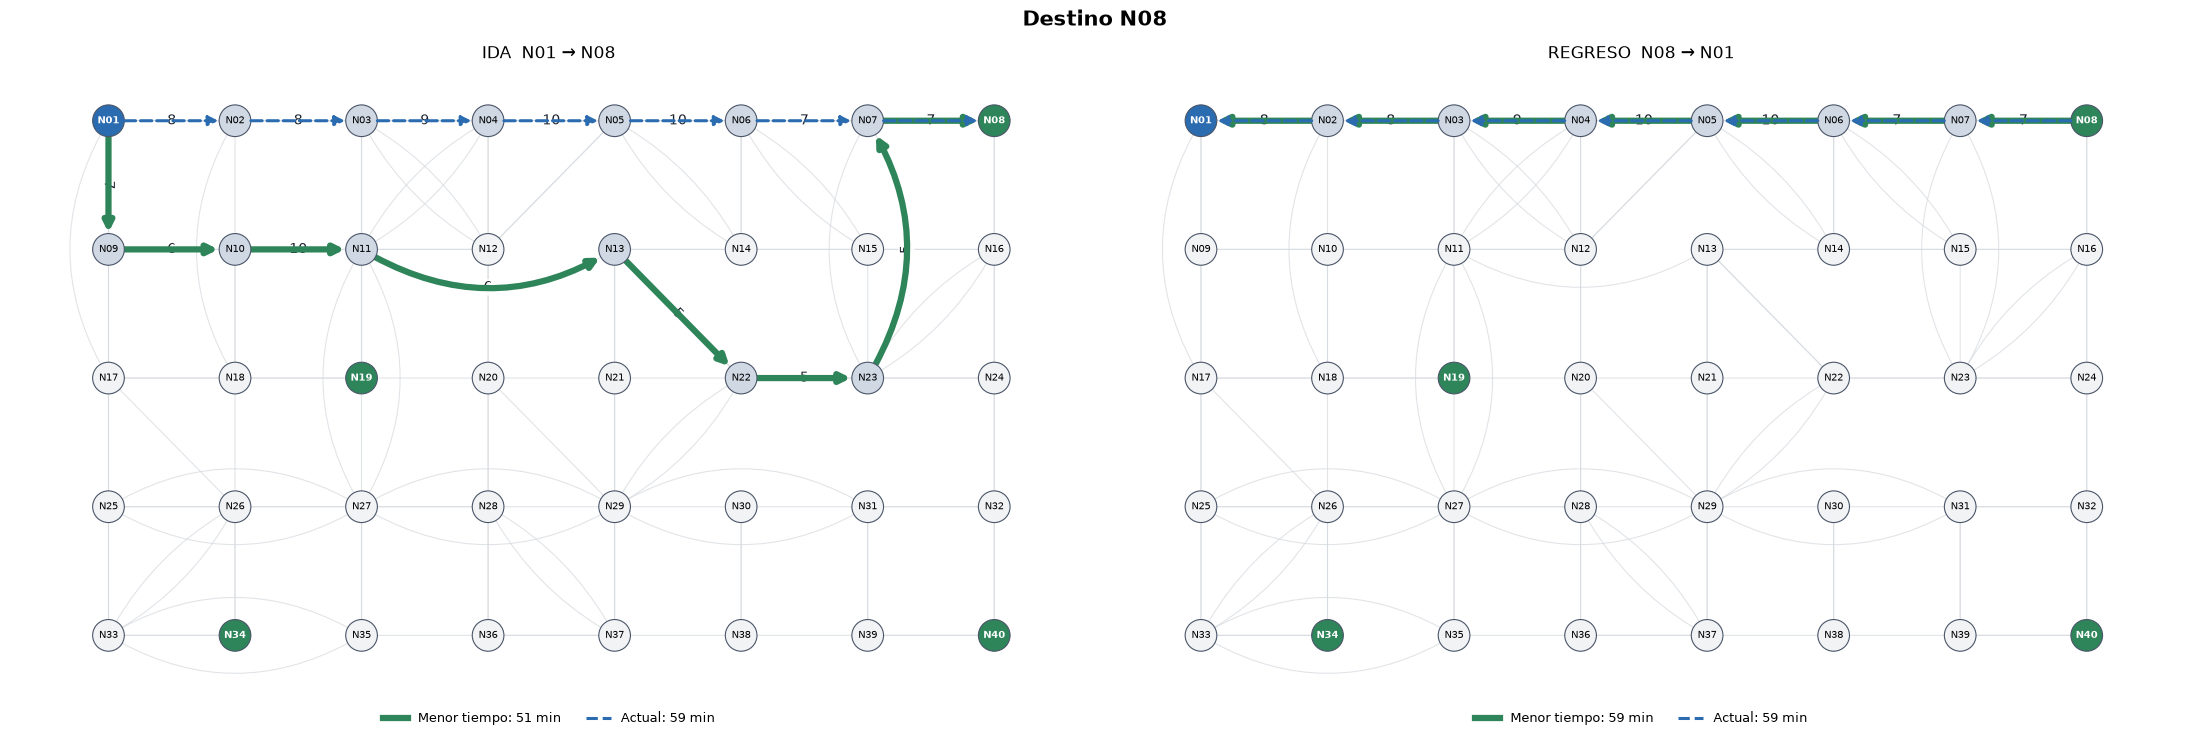

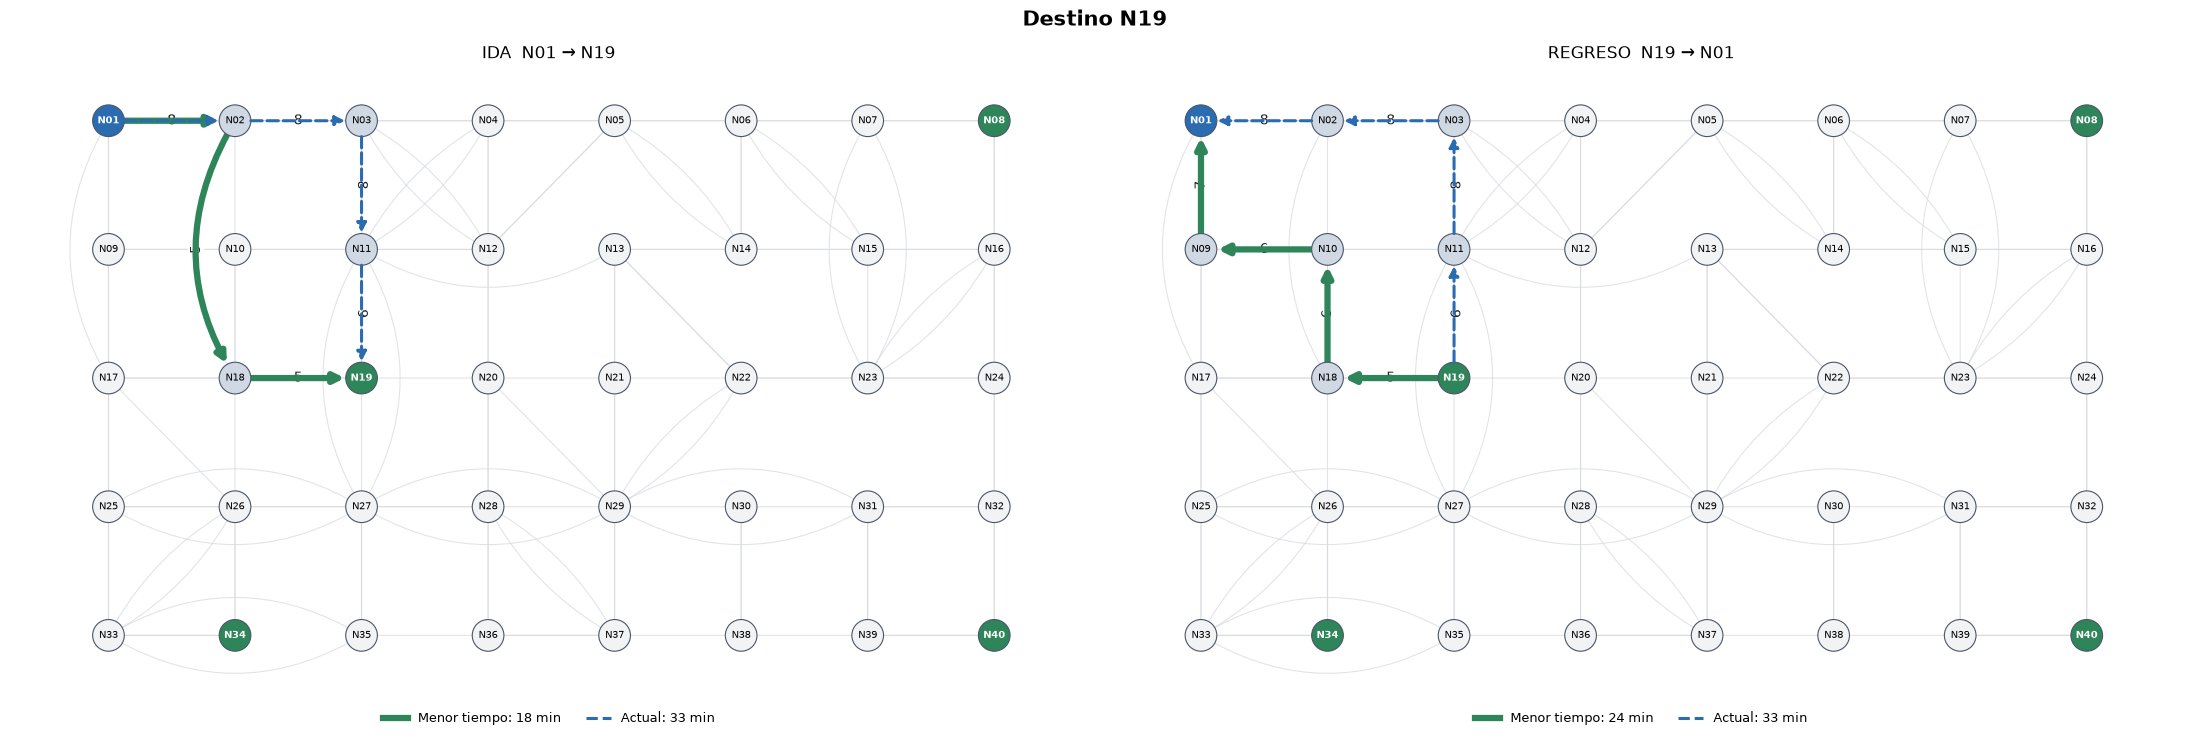

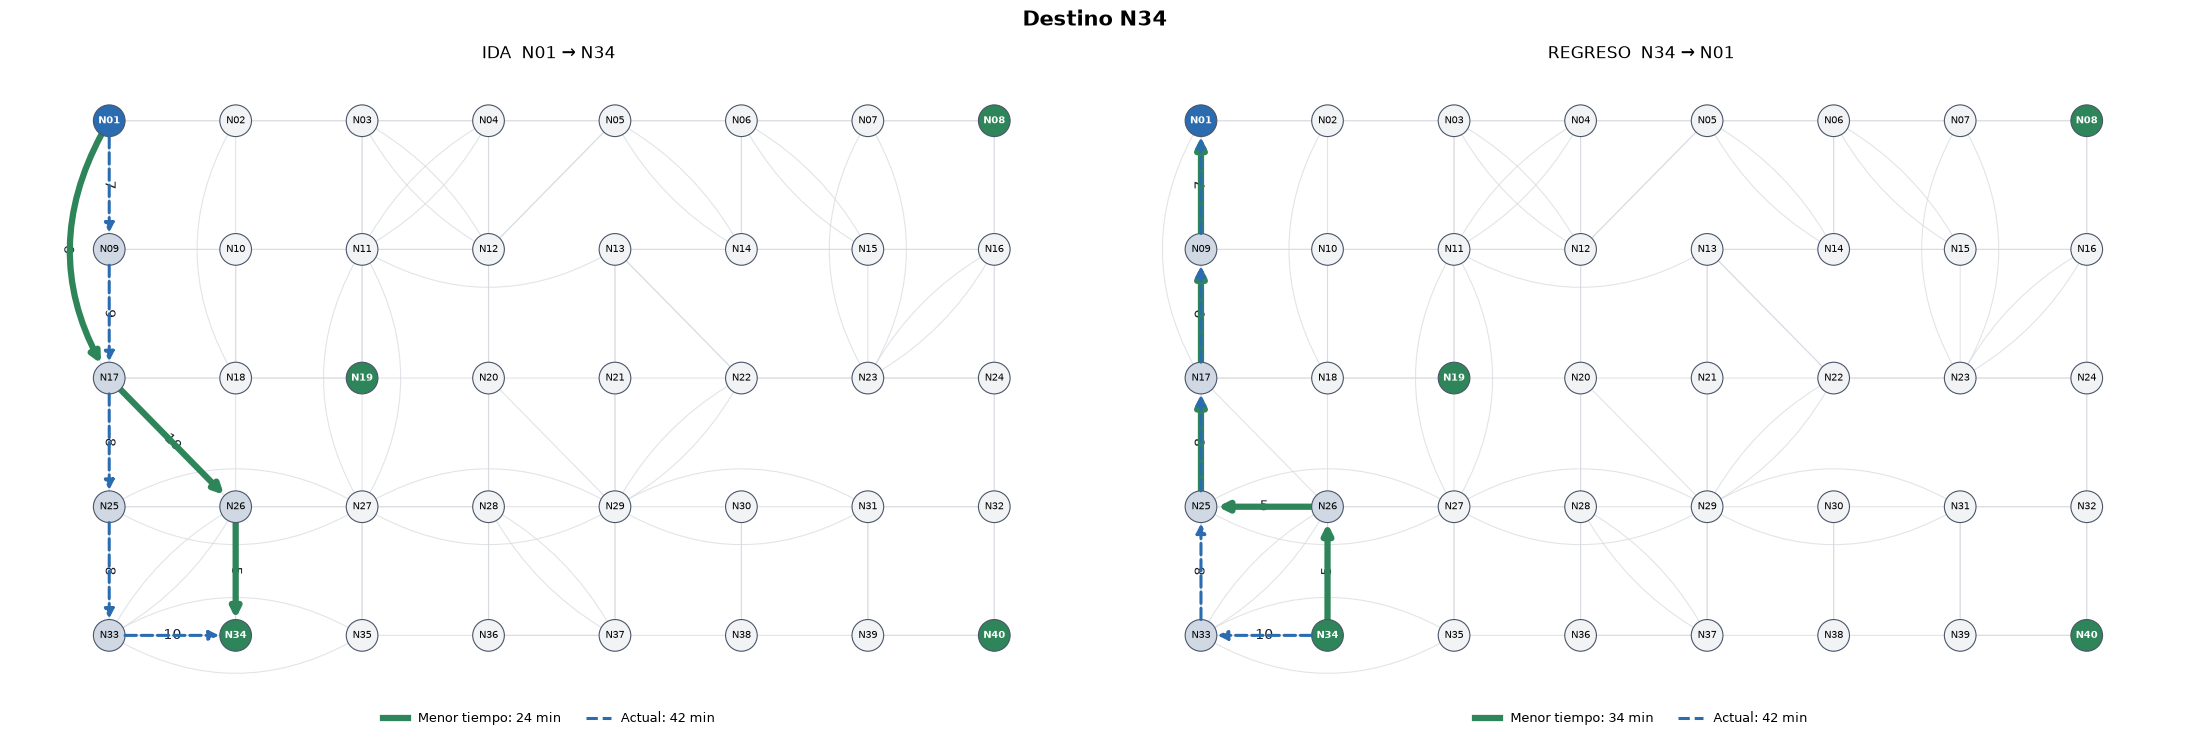

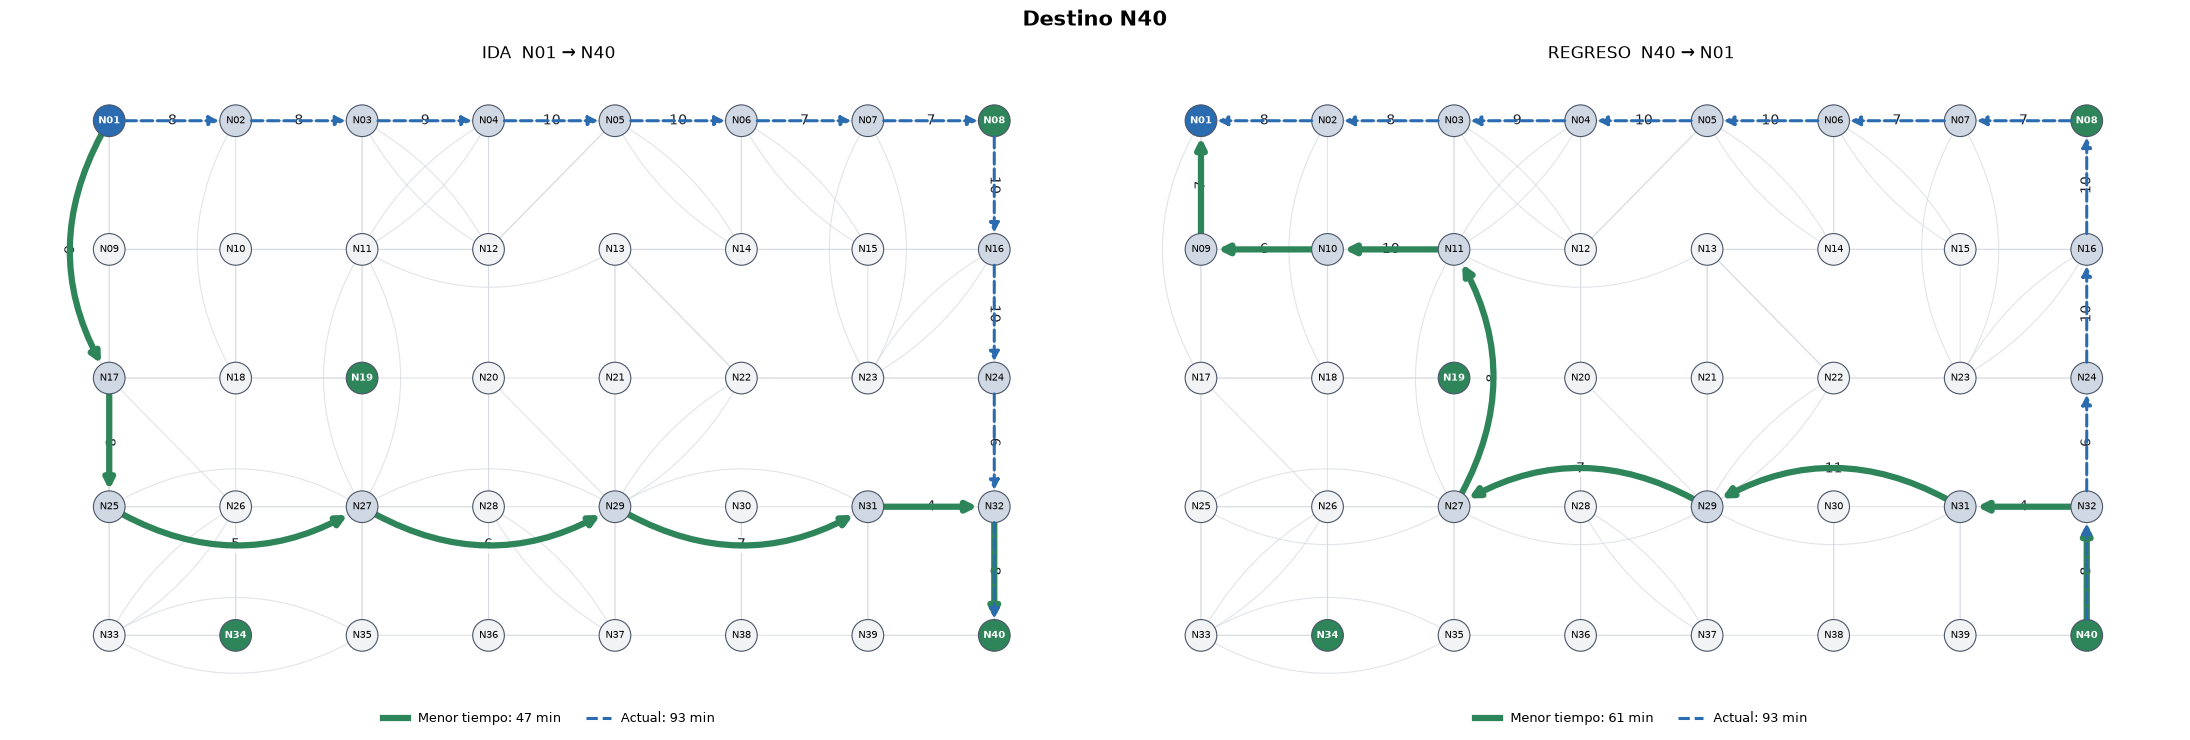

In [9]:
def ruta_optima(origen, destino):
    camino = nx.dijkstra_path(G, origen, destino, weight="peso")
    return camino, nx.path_weight(G, camino, weight="peso")

VERDE, AZUL = "#2f855a", "#2b6cb0"
optimas = {}

for destino, actual in g.RUTAS_ACTUALES.items():
    opt_ida, t_opt_ida = ruta_optima(g.BODEGA, destino)
    opt_reg, t_opt_reg = ruta_optima(destino, g.BODEGA)
    t_act = validacion_actual.loc[destino, "ida (min)"]
    optimas[destino] = (opt_ida, t_opt_ida, opt_reg, t_opt_reg)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(22, 7.5))
    g.dibujar_rutas(G, [
        (opt_ida, VERDE, f"Menor tiempo: {t_opt_ida:g} min", "solid"),
        (actual, AZUL, f"Actual: {t_act:g} min", "dashed"),
    ], ax=ax1, titulo=f"IDA  {g.BODEGA} → {destino}")
    g.dibujar_rutas(G, [
        (opt_reg, VERDE, f"Menor tiempo: {t_opt_reg:g} min", "solid"),
        (actual[::-1], AZUL, f"Actual: {t_act:g} min", "dashed"),
    ], ax=ax2, titulo=f"REGRESO  {destino} → {g.BODEGA}")
    fig.suptitle(f"Destino {destino}", fontsize=15, fontweight="bold")
    plt.tight_layout()
    plt.show()

### Resumen comparativo

In [10]:
filas = []
for destino, (opt_ida, t_opt_ida, opt_reg, t_opt_reg) in optimas.items():
    t_act = validacion_actual.loc[destino, "ida (min)"]
    filas.append({
        "destino": destino,
        "actual ida": t_act,
        "óptima ida": t_opt_ida,
        "actual regreso": t_act,
        "óptima regreso": t_opt_reg,
        "ahorro ciclo (min)": 2 * t_act - (t_opt_ida + t_opt_reg),
        "ruta óptima ida": " → ".join(opt_ida),
        "ruta óptima regreso": " → ".join(opt_reg),
        "¿regreso = ida invertida?": opt_reg == opt_ida[::-1],
    })
comparacion = pd.DataFrame(filas).set_index("destino")
comparacion

,actual ida,óptima ida,actual regreso,óptima regreso,ahorro ciclo (min),ruta óptima ida,ruta óptima regreso,¿regreso = ida invertida?
destino,,,,,,,,
N08,59.0,51.0,59.0,59.0,8.0,N01 → N09 → N10 → N11 → N13 → N22 → N23 → N07 ...,N08 → N07 → N06 → N05 → N04 → N03 → N02 → N01,False
N19,33.0,18.0,33.0,24.0,24.0,N01 → N02 → N18 → N19,N19 → N18 → N10 → N09 → N01,False
N34,42.0,24.0,42.0,34.0,26.0,N01 → N17 → N26 → N34,N34 → N26 → N25 → N17 → N09 → N01,False
N40,93.0,47.0,93.0,61.0,78.0,N01 → N17 → N25 → N27 → N29 → N31 → N32 → N40,N40 → N32 → N31 → N29 → N27 → N11 → N10 → N09 ...,False


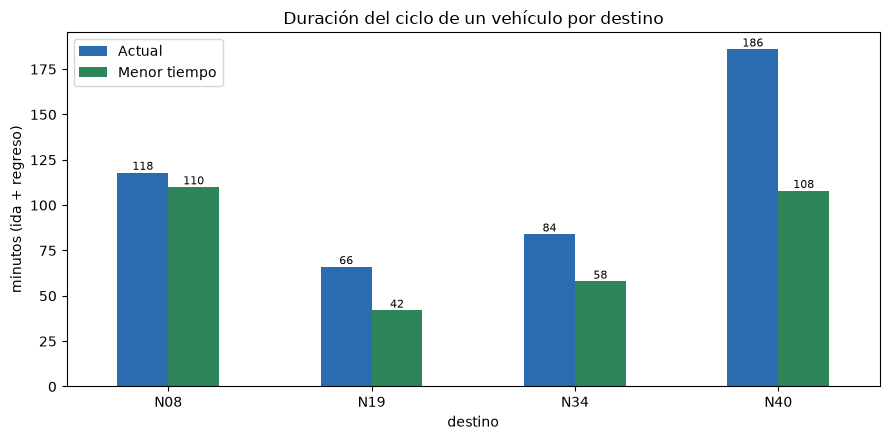

Ciclo promedio (destinos equiprobables): actual = 113.5 min, menor tiempo = 79.5 min


In [11]:
ciclos = pd.DataFrame({
    "Actual": 2 * validacion_actual["ida (min)"],
    "Menor tiempo": comparacion["óptima ida"] + comparacion["óptima regreso"],
})
ax = ciclos.plot.bar(figsize=(9, 4.5), color=[AZUL, VERDE], rot=0)
ax.set_ylabel("minutos (ida + regreso)")
ax.set_title("Duración del ciclo de un vehículo por destino")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%g", fontsize=8)
plt.tight_layout()
plt.show()

print(f"Ciclo promedio (destinos equiprobables): actual = {ciclos['Actual'].mean():.1f} min, "
      f"menor tiempo = {ciclos['Menor tiempo'].mean():.1f} min")

## Conclusiones de este notebook

- La red tiene 40 puntos y es **fuertemente conexa**: desde cualquier punto se puede llegar a cualquier otro.
- Hay calles de **un solo sentido** y tramos con **tiempos distintos según el sentido**, por lo que el grafo
  debe ser dirigido y la ida y el regreso se deben calcular por separado.
- Las rutas actuales son **válidas** de ida y regreso, pero ninguna es la de menor tiempo **de ida**; en el regreso
  solo la de N08 coincide con la de menor tiempo (59 min).
- En varios destinos la mejor ruta de regreso **no es** la ida invertida, porque usa calles de un solo sentido o
  tramos más rápidos en un sentido que en el otro.
- La ruta actual a N40 (93 min de ida) **impide cumplir el umbral de 75 minutos**; la de menor tiempo lo reduce a la mitad.
- El ciclo promedio de un vehículo baja de forma importante con las rutas de menor tiempo; esto se traducirá en más
  capacidad de la flota en la simulación (fase 5).